## **1. Persiapan dan Pemuatan Data**

In [1]:
# Memuat semua library yang dibutuhkan untuk proses training dan testing model
import time
import copy
import json
import csv
import random
import torch
import torch.nn as nn
import torch.nn.functional as func
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from datetime import datetime
from PIL import Image
from torch.autograd import Variable
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.metrics import f1_score, confusion_matrix

# Pengaturan untuk menentukan device komputasi yang akan digunakan
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Untuk melihat perubahan ukuran dan jumlah parameter pada suatu arsitektur NN
!pip install torchinfo
from torchinfo import summary

# Memuat library yang akan digunakan untuk kemudahan penyimpanan ke google drive
import os
import glob
from google.colab import drive
drive.mount("/content/drive")

# Memuat beberapa library untuk keperluan konversi dan quantization dengan ONNX
!pip install onnxscript
!pip install --upgrade onnxruntime onnxruntime-gpu
import onnx
import onnxruntime
from onnxruntime.quantization import quantize_dynamic, quantize_static, QuantType, QuantFormat, CalibrationDataReader
from onnxruntime.quantization.shape_inference import quant_pre_process
import torch.onnx

Using device: cpu
Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 29.6 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 r

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.7/246.7 MB 5.1 MB/s eta 0:00:00


In [2]:
torch.manual_seed(42)

In [3]:
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Version (via PyTorch): {torch.version.cuda}")
print(f"ONNX Runtime Version: {onnxruntime.__version__}")

PyTorch Version: 2.11.0+cpu
CUDA Version (via PyTorch): None
ONNX Runtime Version: 1.30.0


In [4]:
# Mengunduh dataset (Images & Labels) dan memasukkannya ke dalam variable
train_data = datasets.CIFAR10(root ='/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/Cifar10_Dataset', train = True,
                               transform = transforms.ToTensor(),
                               download = True)

test_data = datasets.CIFAR10(root ='/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/Cifar10_Dataset', train = False,
                              transform = transforms.ToTensor(), download = True)

In [5]:
# Mengecek ukuran dari setiap kelompok data
print("Ukuran training set : {}x{}x{}x{}x{}".format(len(train_data), len(train_data[0]),
                                                    len(train_data[0][0]), len(train_data[0][0][0]),
                                                    len(train_data[0][0][0][0])))
print("Ukuran testing set : {}x{}x{}x{}x{}".format(len(test_data), len(test_data[0]),
                                                   len(test_data[0][0]), len(test_data[0][0][0]),
                                                   len(test_data[0][0][0][0])))

# Catatan:
# - Dimensi ke-0 = Banyaknya data
# - Dimensi ke-1 = Images[3x32x32] + Labels[1]

Ukuran training set : 50000x2x3x32x32
Ukuran testing set : 10000x2x3x32x32


In [6]:
# Data constants
input_size = 32 * 32
input_channel = 3
num_classes = 10

# Hyperparameters
batch_size = 128

# Data loaders
train_loader = DataLoader(train_data, batch_size, shuffle=True)
test_loader = DataLoader(test_data, 1, shuffle=False)

In [7]:
# Pembuatan fungsi untuk melakukan konversi images dari [-1, 1] ke [0, 1]
# untuk kebutuhan visualisasi
def img_convert(input_tensor):
  image = input_tensor.cpu().clone().detach().numpy()
  # Merubah dari (C,H,W) menjadi (H,W,C)
  image = image.transpose(1, 2, 0)
  # Sebagai catatan untuk ditampilkan pada matplotlib rentang nilai bisa dibuat menjadi [0,1] atau [0,255]
  return image

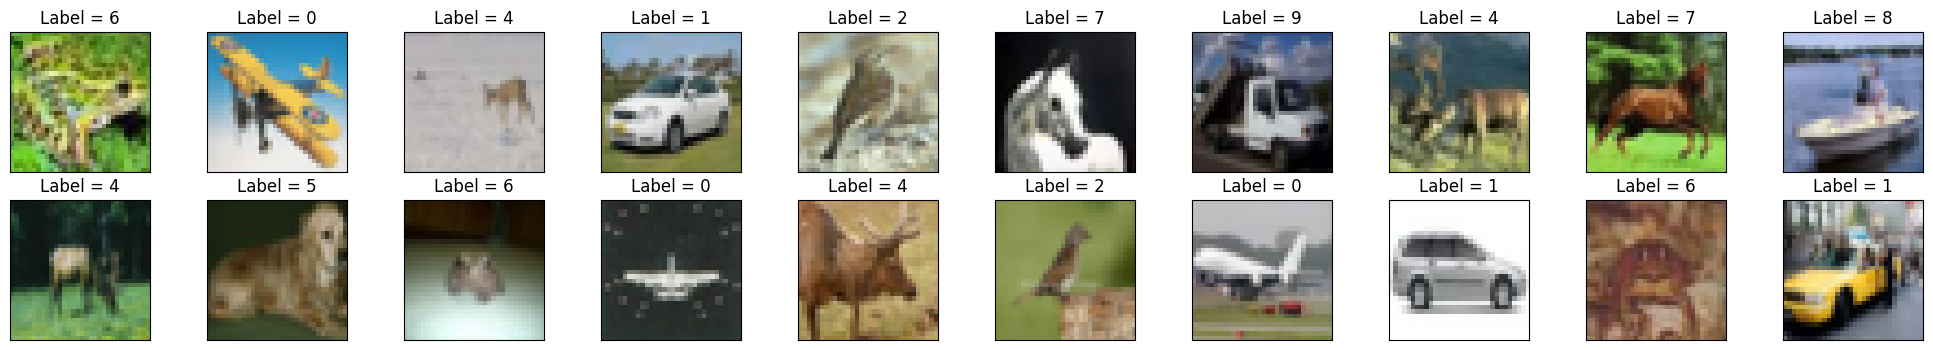

In [8]:
# Menampilkan data yang sudah dimuat mempertimbangkan iterator object
dataiter = iter(train_loader)
images, labels = next(dataiter)
fig = plt.figure(figsize=(25, 4))
for idx in range(20):
  ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
  plt.imshow(img_convert(images[idx]))
  ax.set_title("Label = " + str(labels[idx].item()))

In [9]:
# Pendefinisian fungsi untuk memperoleh ukuran dari quantized model
def get_file_size_mb(file_path):
  return os.path.getsize(file_path)

In [10]:
# Tentukan folder penyimpanan log di Google Drive Anda
LOG_DIR = "/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs"
os.makedirs(LOG_DIR, exist_ok=True)

CSV_LOG_PATH = os.path.join(LOG_DIR, "cifar10_quantization_benchmark.csv")
JSON_LOG_PATH = os.path.join(LOG_DIR, "cifar10_quantization_benchmark.json")

FIGURE_DIR = os.path.join(LOG_DIR, "confusion_matrices")
os.makedirs(FIGURE_DIR, exist_ok=True)

# Inisialisasi header file CSV jika belum dibuat
CSV_HEADERS = ["timestamp","seed","framework","method","runtime_backend","quant_scheme",
               "accuracy","macro_precision","macro_recall","macro_f1","model_size_mb",
               "size_reduction_pct","latency_mean_ms","latency_std_ms"]

if not os.path.exists(CSV_LOG_PATH):
  with open(CSV_LOG_PATH, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(CSV_HEADERS)
  print(f"---> File log CSV berhasil diinisialisasi: {CSV_LOG_PATH}")

## **2. Pendefinisian Model**

In [11]:
# Pembuatan model untuk CNN yang merujuk pada VGG-16Layer
# - in_channels (int) - Jumlah dari channels dalam data citra masukkan.
# - num_classes (int) - Jumlah class target yang akan digunakan sebagai neuron output pada FC akhir.
class VGG16(nn.Module):
  def __init__(self, in_channels=3, num_classes=10):
    super(VGG16, self).__init__()
    self.layer1 = nn.Sequential(
        nn.Conv2d(in_channels, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU())
    self.layer2 = nn.Sequential(
        nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer3 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU())
    self.layer4 = nn.Sequential(
        nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer5 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer6 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer7 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer8 = nn.Sequential(
        nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer9 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer10 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer11 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer12 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer13 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(1*1*512, 4096),
        nn.ReLU())
    self.fc1 = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(4096, 4096),
        nn.ReLU())
    self.fc2= nn.Sequential(
        nn.Linear(4096, num_classes))

  def forward(self, x):
    out = self.layer1(x)
    out = self.layer2(out)
    out = self.layer3(out)
    out = self.layer4(out)
    out = self.layer5(out)
    out = self.layer6(out)
    out = self.layer7(out)
    out = self.layer8(out)
    out = self.layer9(out)
    out = self.layer10(out)
    out = self.layer11(out)
    out = self.layer12(out)
    out = self.layer13(out)
    out = out.reshape(out.size(0), -1) #Flatten
    out = self.fc(out)
    out = self.fc1(out)
    out = self.fc2(out)
    return out

In [12]:
# Percobaan untuk melakukan setting arsitektur VGG pada suatu variabel
model = VGG16(input_channel,num_classes).to(device)

# Menampilkan summary proses pada setiap block
summary(model, input_size=(batch_size, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
VGG16                                    [128, 10]                 --
├─Sequential: 1-1                        [128, 64, 32, 32]         --
│    └─Conv2d: 2-1                       [128, 64, 32, 32]         1,792
│    └─BatchNorm2d: 2-2                  [128, 64, 32, 32]         128
│    └─ReLU: 2-3                         [128, 64, 32, 32]         --
├─Sequential: 1-2                        [128, 64, 16, 16]         --
│    └─Conv2d: 2-4                       [128, 64, 32, 32]         36,928
│    └─BatchNorm2d: 2-5                  [128, 64, 32, 32]         128
│    └─ReLU: 2-6                         [128, 64, 32, 32]         --
│    └─MaxPool2d: 2-7                    [128, 64, 16, 16]         --
├─Sequential: 1-3                        [128, 128, 16, 16]        --
│    └─Conv2d: 2-8                       [128, 128, 16, 16]        73,856
│    └─BatchNorm2d: 2-9                  [128, 128, 16, 16]        256
│

In [13]:
# Pendefinisian fungsi untuk mengunci seluruh random generator untuk memastikan reproduktibilitas
# penuh pada inisialisasi bobot, data loader shuffle, dan perhitungan CUDA.
def set_deterministic_seed(seed: int):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
  print(f"\n---> [SYSTEM] Deterministic Random Seed berhasil diset ke: {seed}")

In [14]:
def evaluate_onnx_model(model_path, data_loader, num_classes=10):
    session = onnxruntime.InferenceSession(model_path, providers=CPU_PROVIDER)
    input_name = session.get_inputs()[0].name
    output_name = session.get_outputs()[0].name

    all_preds = []
    all_targets = []

    for images, labels in data_loader:
        images_np = images.cpu().numpy()
        ort_outs = session.run([output_name], {input_name: images_np})
        preds = np.argmax(ort_outs[0], axis=1)

        all_preds.extend(preds)
        all_targets.extend(labels.numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    acc = np.mean(all_preds == all_targets)
    macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

    # Hitung Per-class Precision & Recall
    precisions = []
    recalls = []
    for i in range(num_classes):
        tp = np.sum((all_preds == i) & (all_targets == i))
        fp = np.sum((all_preds == i) & (all_targets != i))
        fn = np.sum((all_preds != i) & (all_targets == i))
        precisions.append(tp / (tp + fp + 1e-8))
        recalls.append(tp / (tp + fn + 1e-8))

    macro_precision = np.mean(precisions)
    macro_recall = np.mean(recalls)

    return acc, macro_precision, macro_recall, macro_f1

In [15]:
# Benchmarking Latensi CPU ONNX Standar
def benchmark_onnx_latency_cpu(model_path, sample_shape=(1, 3, 32, 32), num_warmup=20, num_runs=100):
  session = onnxruntime.InferenceSession(model_path, providers=CPU_PROVIDER)
  input_name = session.get_inputs()[0].name
  output_name = session.get_outputs()[0].name
  input_data = np.random.randn(*sample_shape).astype(np.float32)

  # Warm-up phase
  for _ in range(num_warmup):
    _ = session.run([output_name], {input_name: input_data})

  latencies = []
  for _ in range(num_runs):
    t0 = time.perf_counter()
    _ = session.run([output_name], {input_name: input_data})
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000.0)

  latencies = np.array(latencies)
  return latencies.mean(), latencies.std()

In [16]:
# Evaluasi Lengkap Ground Truth & Prediksi untuk ONNX
def get_all_predictions_onnx(model_path, data_loader):
  session = onnxruntime.InferenceSession(model_path, providers=['CPUExecutionProvider'])
  input_name = session.get_inputs()[0].name
  output_name = session.get_outputs()[0].name

  all_preds = []
  all_targets = []

  for images, labels in data_loader:
    images_np = images.numpy()
    ort_outs = session.run([output_name], {input_name: images_np})
    preds = np.argmax(ort_outs[0], axis=1)

    all_preds.extend(preds)
    all_targets.extend(labels.numpy())

  return np.array(all_targets), np.array(all_preds)

In [17]:
# Menampilkan dan menyimpan Confusion Matrix (default: dinormalisasi per-kelas 0.0 - 1.0)
def plot_and_save_confusion_matrix(y_true, y_pred, title, save_path=None, normalize=True):
  CIFAR10_CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

  cm = confusion_matrix(y_true, y_pred)
  fmt = 'd'
  if normalize:
    cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    fmt = '.2f'

  plt.figure(figsize=(9, 7))
  sns.heatmap(
      cm,
      annot=True,
      fmt=fmt,
      cmap='Blues',
      xticklabels=CIFAR10_CLASSES,
      yticklabels=CIFAR10_CLASSES,
      cbar=True
  )
  plt.title(title, fontsize=14, pad=12)
  plt.xlabel('Predicted Label', fontsize=12)
  plt.ylabel('True Ground Truth Label', fontsize=12)
  plt.tight_layout()

  if save_path:
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"[CM SAVED] Confusion matrix tersimpan di: {save_path}")
  plt.show()

In [18]:
# Menganalisis dan mencetak kelas CIFAR-10 yang paling terdampak (mengalami penurunan
# akurasi terbesar) akibat proses kuantisasi dibandingkan baseline FP32.
def analyze_most_degraded_classes(y_true, y_pred_fp32, y_pred_quant, method_name="Quantized Model"):
  CIFAR10_CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

  cm_fp32 = confusion_matrix(y_true, y_pred_fp32, normalize='true')
  cm_quant = confusion_matrix(y_true, y_pred_quant, normalize='true')

  acc_per_class_fp32 = cm_fp32.diagonal() * 100.0
  acc_per_class_quant = cm_quant.diagonal() * 100.0
  diff = acc_per_class_quant - acc_per_class_fp32 # Nilai negatif mengindikasikan penurunan

  print(f"\n{'='*70}")
  print(f" ANALISIS DEGRADASI AKURASI PER-KELAS: {method_name} vs Baseline FP32")
  print(f"{'='*70}")
  print(f"{'Class':<12} | {'FP32 Acc (%)':<14} | {'Quant Acc (%)':<14} | {'Degradasi / Delta (%)':<18}")
  print(f"{'-'*70}")

  sorted_indices = np.argsort(diff) # Urutkan dari yang paling turun
  for idx in sorted_indices:
    cls_name = CIFAR10_CLASSES[idx]
    delta_str = f"{diff[idx]:+.2f}%"
    print(f"{cls_name:<12} | {acc_per_class_fp32[idx]:<14.2f} | {acc_per_class_quant[idx]:<14.2f} | {delta_str:<18}")

  most_affected_idx = sorted_indices[0]
  print(f"{'-'*70}")
  print(f"---> KELAS PALING TERDAMPAK: '{CIFAR10_CLASSES[most_affected_idx]}' dengan delta {diff[most_affected_idx]:.2f}%\n")

In [19]:
# Pendefinisian fungsi untuk menyimpan satu baris data eksperimen ke CSV dan memperbarui riwayat di JSON.
def log_experiment_result(seed: int, framework: str, method: str, runtime_backend: str, quant_scheme: str,
                          accuracy: float, macro_precision: float, macro_recall: float, macro_f1: float,
                          model_size_mb: float, baseline_size_mb: float, latency_mean_ms: float,
                          latency_std_ms: float):

  # Hitung persentase kompresi ukuran model terhadap baseline
  size_reduction = (1.0 - (model_size_mb / baseline_size_mb)) * 100.0 if baseline_size_mb > 0 else 0.0
  now_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

  # Siapkan payload baris data
  row_dict = {
      "timestamp": now_str,
      "seed": seed,
      "framework": framework,
      "method": method,
      "runtime_backend": runtime_backend,
      "quant_scheme": quant_scheme,
      "accuracy": round(float(accuracy), 4),
      "macro_precision": round(float(macro_precision), 4),
      "macro_recall": round(float(macro_recall), 4),
      "macro_f1": round(float(macro_f1), 4),
      "model_size_mb": round(float(model_size_mb), 2),
      "size_reduction_pct": round(float(size_reduction), 2),
      "latency_mean_ms": round(float(latency_mean_ms), 2),
      "latency_std_ms": round(float(latency_std_ms), 2)
  }

  # 1. Append ke File CSV
  with open(CSV_LOG_PATH, mode="a", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=CSV_HEADERS)
    writer.writerow(row_dict)

  # 2. Append ke File JSON
  all_logs = []
  if os.path.exists(JSON_LOG_PATH):
    try:
      with open(JSON_LOG_PATH, mode="r", encoding="utf-8") as jf:
        all_logs = json.load(jf)
    except json.JSONDecodeError:
      all_logs = []

  all_logs.append(row_dict)
  with open(JSON_LOG_PATH, mode="w", encoding="utf-8") as jf:
    json.dump(all_logs, jf, indent=4)

  print(f"[LOG SUCCESS] {framework} - {method} (Seed: {seed}) tercatat di file eksternal.")

In [20]:
# Calibration Data Reader Sinkron PyTorch
class CIFAR10CalibrationDataReader(CalibrationDataReader):
  def __init__(self, data_loader, model_path, max_samples=100):
    self.data_loader = data_loader
    session = onnxruntime.InferenceSession(model_path, providers=CPU_PROVIDER)
    self.input_name = session.get_inputs()[0].name
    self.data_iter = iter(self.data_loader)
    self.max_samples = max_samples
    self.current_sample = 0

  def get_next(self):
    if self.current_sample >= self.max_samples:
      return None
    try:
      batch = next(self.data_iter)
      images, _ = batch
      self.current_sample += images.shape[0]
      return {self.input_name: images.numpy().astype(np.float32)}
    except StopIteration:
      return None

  def rewind(self):
    self.data_iter = iter(self.data_loader)
    self.current_sample = 0

## **3. Eksekusi Eksperimen Multi-Seed Berulang**

In [21]:
# Isolasi Provider Murni CPU
CPU_PROVIDER = ['CPUExecutionProvider']

# Tentukan daftar seed (3 perulangan independen)
SEEDS = [42, 123, 456, 1337, 2024]
num_epochs_baseline = 20

# Set path untuk penyimpanan model
MODEL_CHECKPOINT_DIR = "/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/model saved (revisi)"


   MEMULAI EKSPERIMEN ONNX UNTUK SEED: 42

---> [SYSTEM] Deterministic Random Seed berhasil diset ke: 42
Checkpoint /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/model saved (revisi)/model_vgg16_fp32_baseline_seed42.pth berhasil dimuat.
[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_fp32_onnx_seed42.png


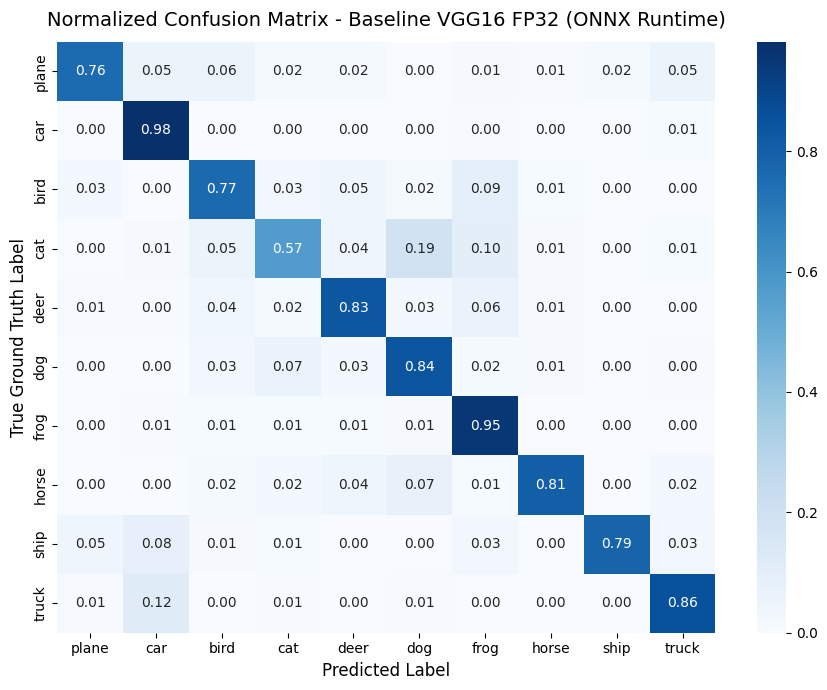

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_onnx_seed42.png


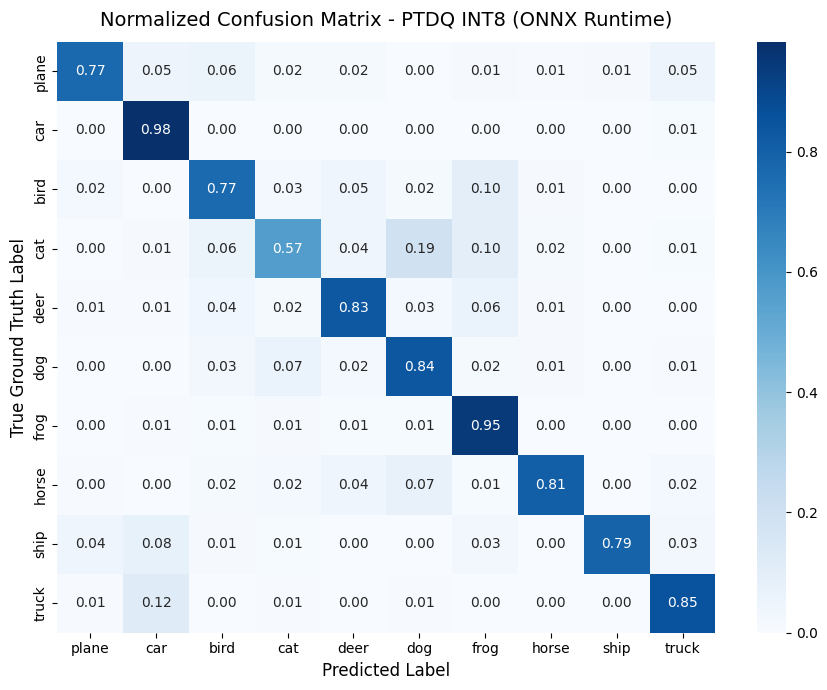


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
frog         | 95.20          | 94.70          | -0.50%            
dog          | 84.10          | 83.70          | -0.40%            
truck        | 85.60          | 85.30          | -0.30%            
deer         | 83.30          | 83.10          | -0.20%            
cat          | 56.80          | 56.80          | +0.00%            
car          | 98.20          | 98.30          | +0.10%            
bird         | 76.50          | 76.60          | +0.10%            
horse        | 80.50          | 80.60          | +0.10%            
plane        | 76.30          | 76.80          | +0.50%            
ship         | 78.50          | 79.00          | +0.50%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'frog' de

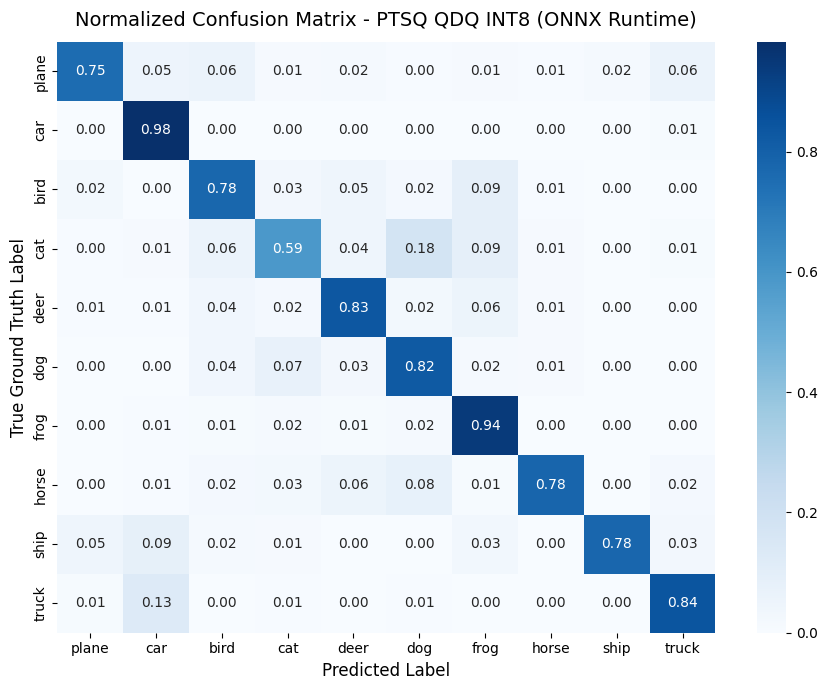


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
horse        | 80.50          | 78.10          | -2.40%            
dog          | 84.10          | 82.50          | -1.60%            
truck        | 85.60          | 84.40          | -1.20%            
frog         | 95.20          | 94.10          | -1.10%            
plane        | 76.30          | 75.40          | -0.90%            
ship         | 78.50          | 77.80          | -0.70%            
car          | 98.20          | 98.30          | +0.10%            
deer         | 83.30          | 83.40          | +0.10%            
bird         | 76.50          | 77.50          | +1.00%            
cat          | 56.80          | 58.70          | +1.90%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'horse' d

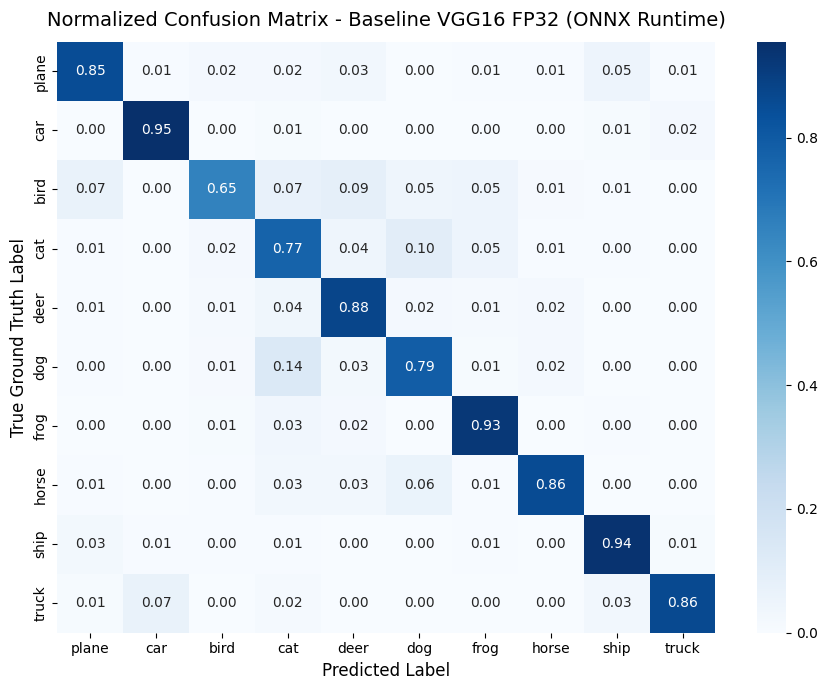

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_onnx_seed123.png


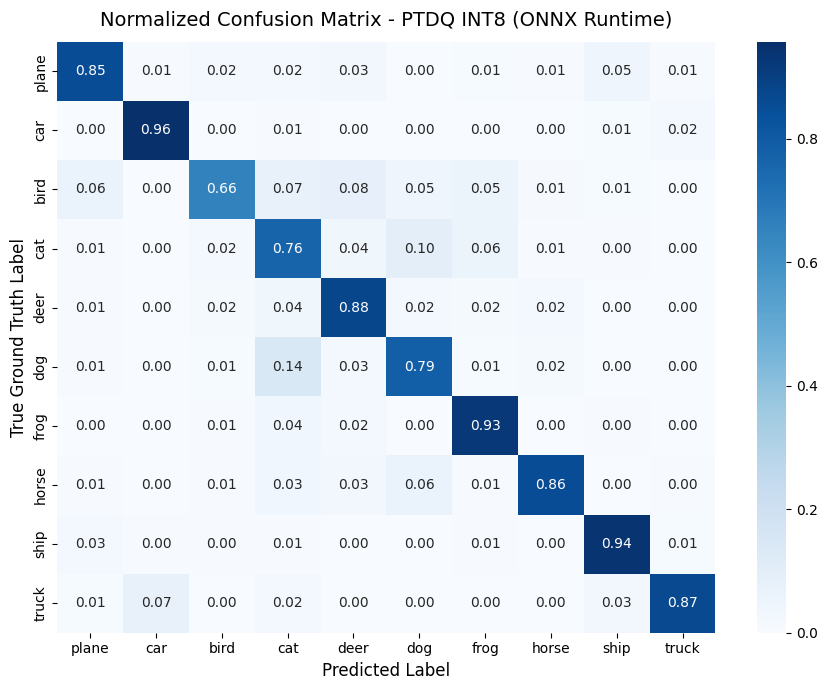


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 79.00          | 78.50          | -0.50%            
cat          | 76.50          | 76.30          | -0.20%            
deer         | 88.00          | 87.80          | -0.20%            
horse        | 85.80          | 85.60          | -0.20%            
plane        | 85.40          | 85.30          | -0.10%            
frog         | 92.50          | 92.50          | +0.00%            
truck        | 86.50          | 86.60          | +0.10%            
ship         | 94.10          | 94.20          | +0.10%            
car          | 95.50          | 95.70          | +0.20%            
bird         | 65.40          | 65.70          | +0.30%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog' den

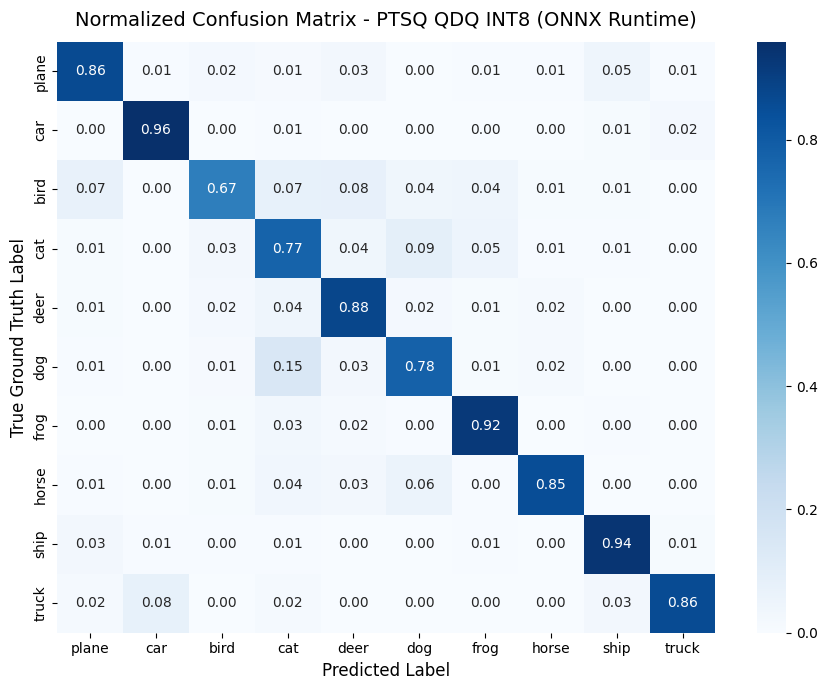


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 79.00          | 77.80          | -1.20%            
truck        | 86.50          | 85.90          | -0.60%            
horse        | 85.80          | 85.40          | -0.40%            
ship         | 94.10          | 93.80          | -0.30%            
frog         | 92.50          | 92.40          | -0.10%            
deer         | 88.00          | 87.90          | -0.10%            
car          | 95.50          | 95.90          | +0.40%            
cat          | 76.50          | 77.10          | +0.60%            
plane        | 85.40          | 86.50          | +1.10%            
bird         | 65.40          | 67.10          | +1.70%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog' den

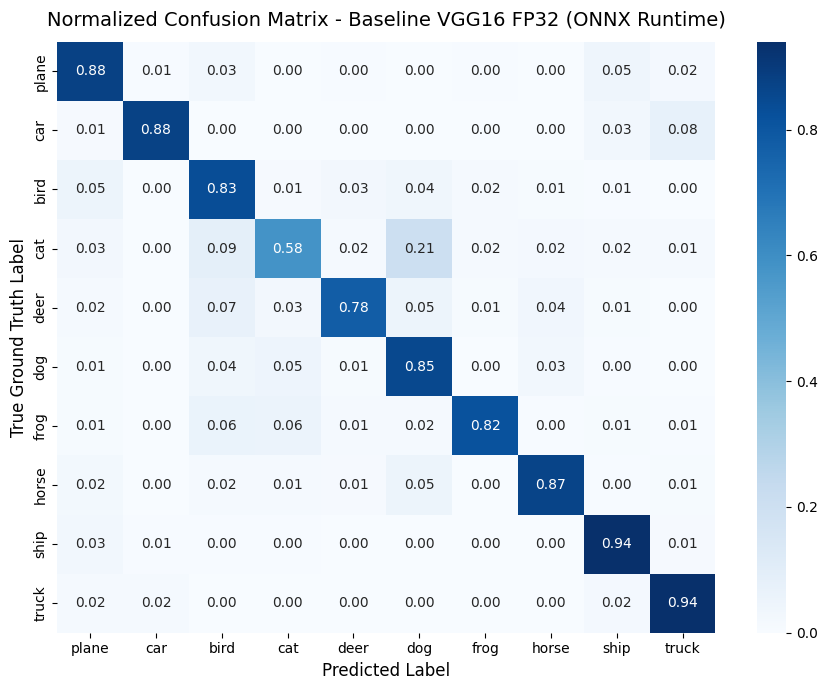

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_onnx_seed456.png


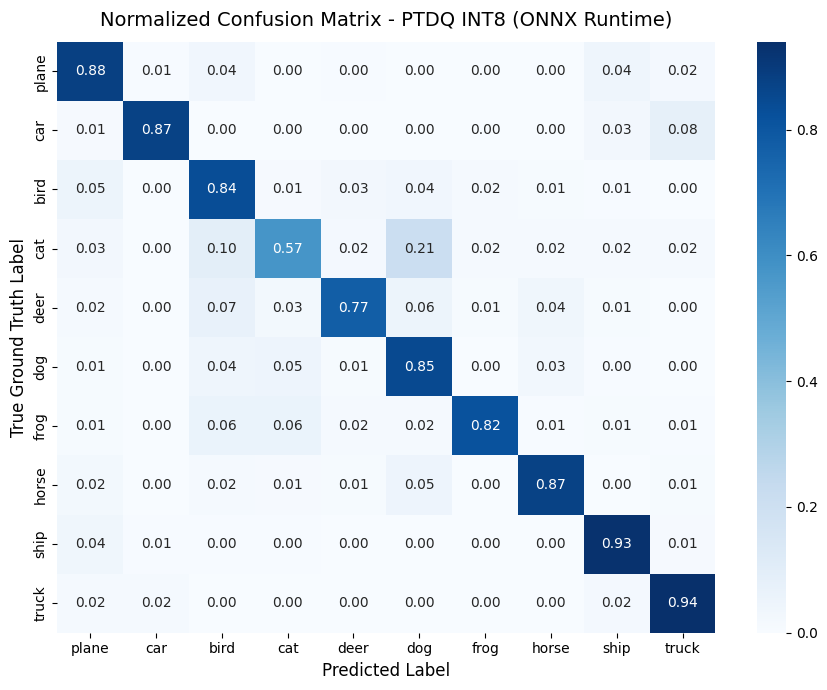


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
cat          | 58.30          | 57.40          | -0.90%            
ship         | 93.80          | 93.20          | -0.60%            
dog          | 85.20          | 84.90          | -0.30%            
deer         | 77.60          | 77.30          | -0.30%            
car          | 87.60          | 87.40          | -0.20%            
frog         | 81.80          | 81.70          | -0.10%            
truck        | 94.00          | 94.00          | +0.00%            
bird         | 83.40          | 83.60          | +0.20%            
plane        | 88.00          | 88.40          | +0.40%            
horse        | 86.70          | 87.40          | +0.70%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'cat' den

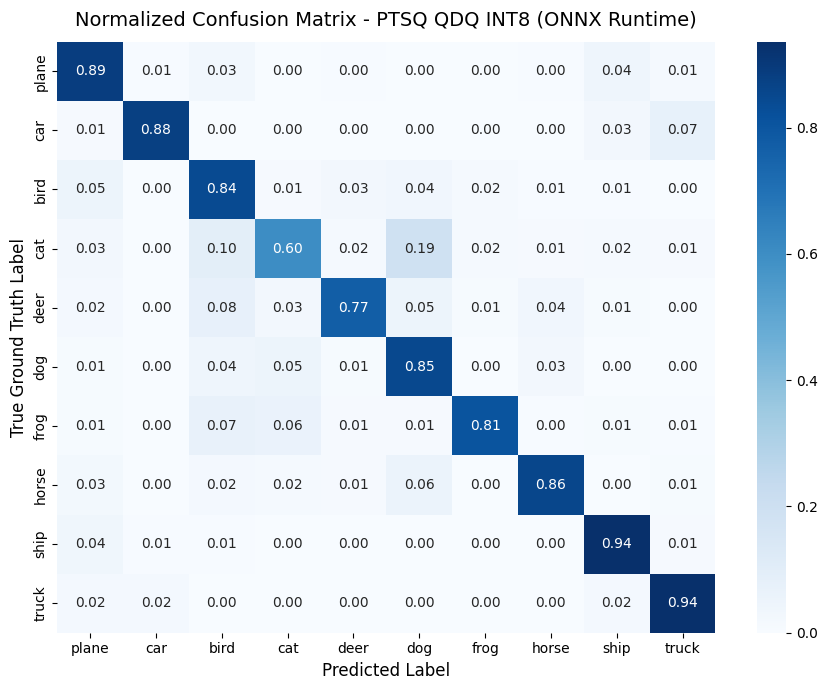


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
frog         | 81.80          | 80.80          | -1.00%            
horse        | 86.70          | 85.90          | -0.80%            
deer         | 77.60          | 76.90          | -0.70%            
truck        | 94.00          | 93.60          | -0.40%            
ship         | 93.80          | 93.50          | -0.30%            
dog          | 85.20          | 85.00          | -0.20%            
car          | 87.60          | 88.00          | +0.40%            
plane        | 88.00          | 88.80          | +0.80%            
bird         | 83.40          | 84.30          | +0.90%            
cat          | 58.30          | 60.30          | +2.00%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'frog' de

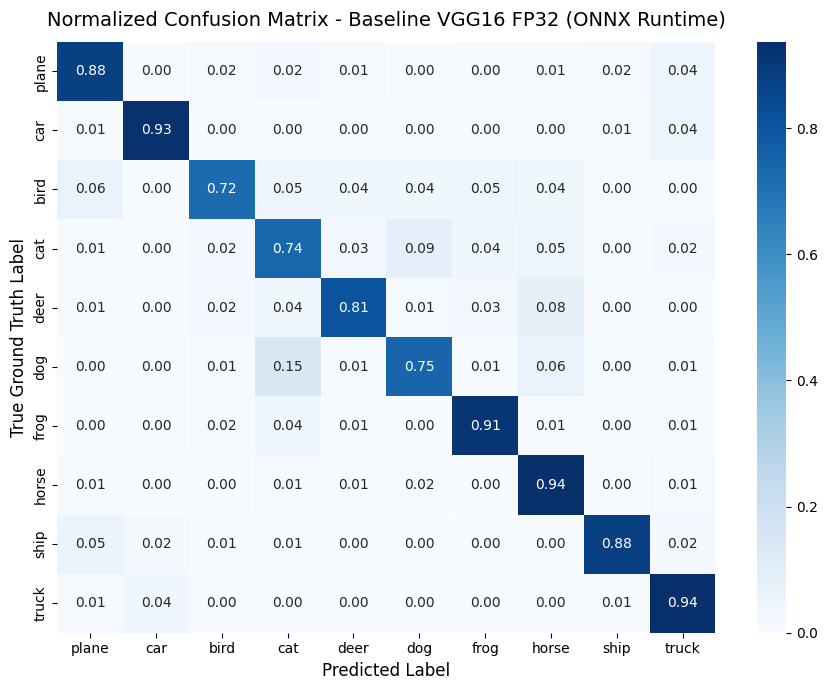

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_onnx_seed1337.png


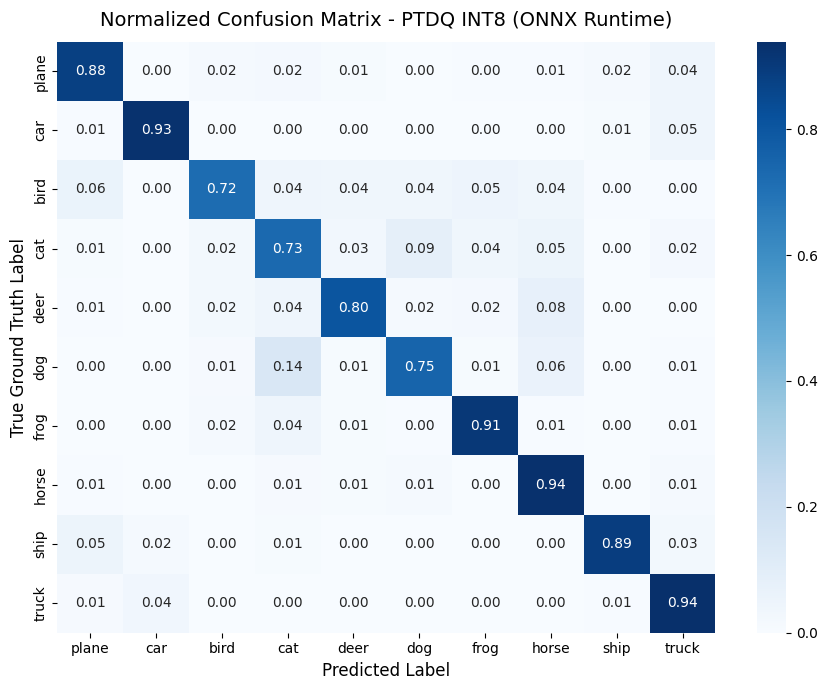


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
cat          | 73.70          | 73.20          | -0.50%            
frog         | 91.40          | 90.90          | -0.50%            
deer         | 80.70          | 80.40          | -0.30%            
bird         | 72.50          | 72.20          | -0.30%            
car          | 93.10          | 93.00          | -0.10%            
horse        | 93.50          | 93.50          | +0.00%            
truck        | 93.70          | 93.90          | +0.20%            
plane        | 88.00          | 88.20          | +0.20%            
dog          | 74.60          | 74.90          | +0.30%            
ship         | 88.20          | 89.00          | +0.80%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'cat' den

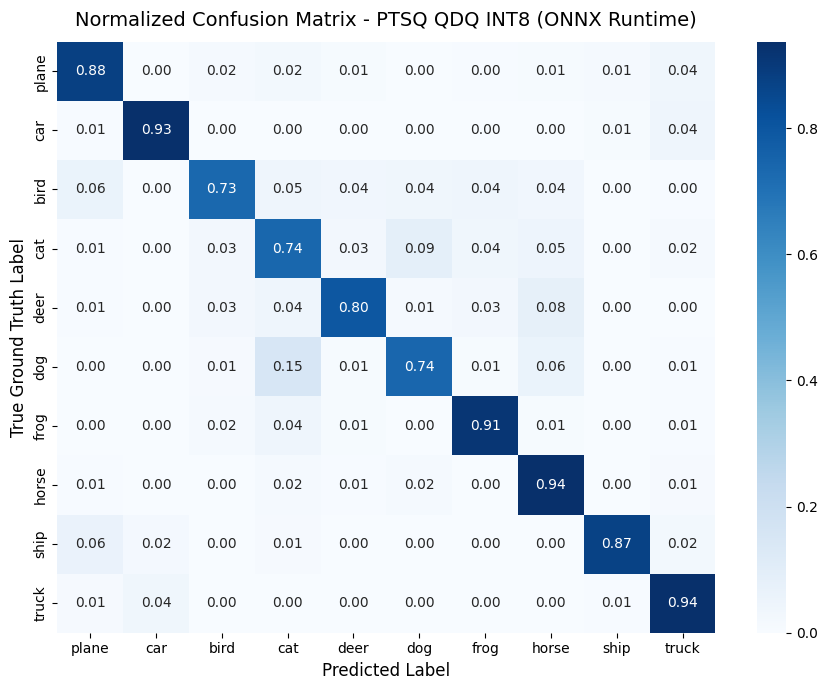


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
deer         | 80.70          | 79.70          | -1.00%            
ship         | 88.20          | 87.30          | -0.90%            
dog          | 74.60          | 74.20          | -0.40%            
frog         | 91.40          | 91.30          | -0.10%            
truck        | 93.70          | 93.70          | +0.00%            
cat          | 73.70          | 73.70          | +0.00%            
plane        | 88.00          | 88.10          | +0.10%            
horse        | 93.50          | 93.60          | +0.10%            
car          | 93.10          | 93.40          | +0.30%            
bird         | 72.50          | 73.30          | +0.80%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'deer' de

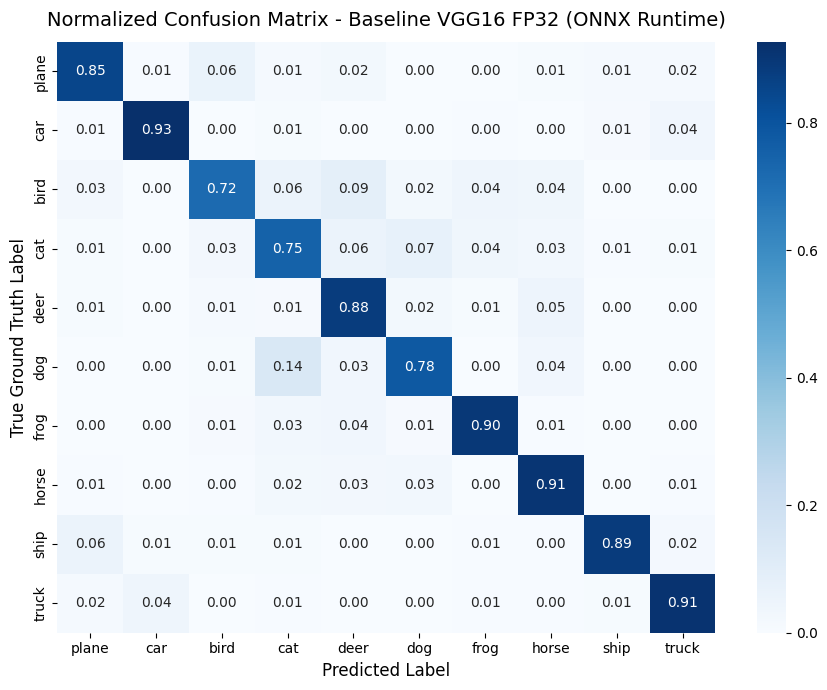

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_onnx_seed2024.png


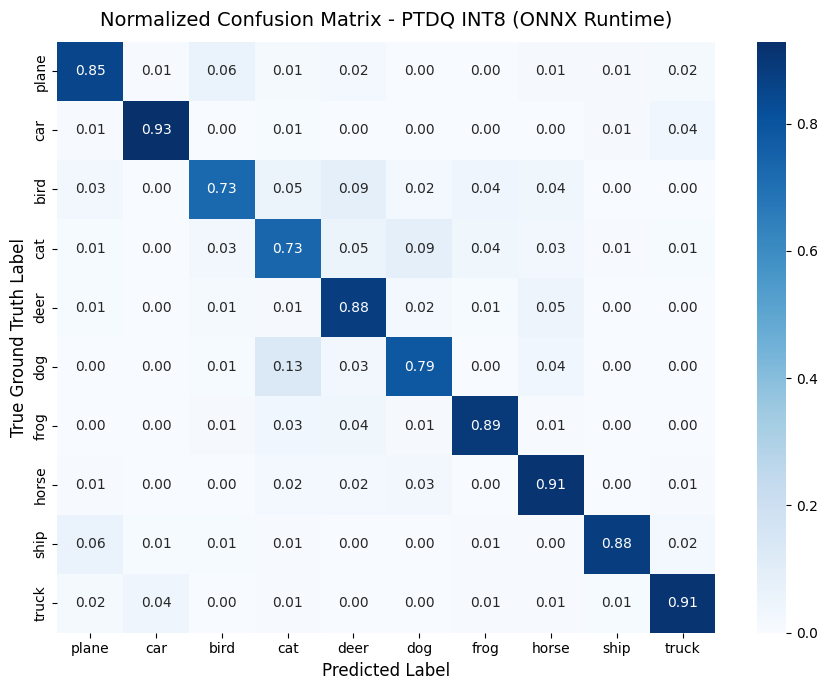


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
cat          | 74.70          | 73.40          | -1.30%            
ship         | 88.60          | 87.90          | -0.70%            
frog         | 89.50          | 89.00          | -0.50%            
deer         | 88.00          | 87.90          | -0.10%            
truck        | 91.30          | 91.20          | -0.10%            
car          | 92.70          | 92.90          | +0.20%            
plane        | 85.10          | 85.50          | +0.40%            
horse        | 90.60          | 91.20          | +0.60%            
dog          | 77.90          | 78.70          | +0.80%            
bird         | 72.00          | 72.90          | +0.90%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'cat' den

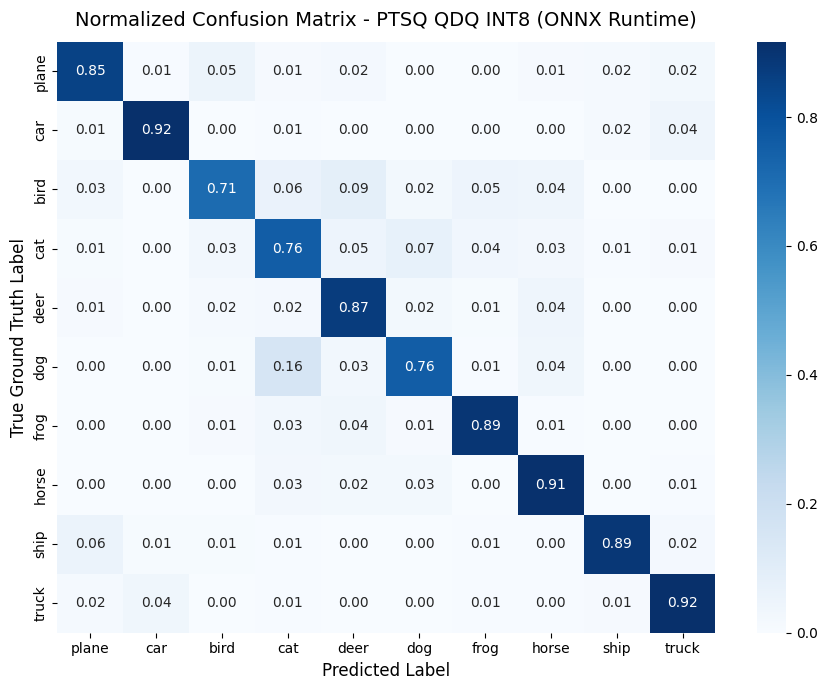


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (ONNX) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 77.90          | 75.70          | -2.20%            
bird         | 72.00          | 70.70          | -1.30%            
car          | 92.70          | 91.50          | -1.20%            
deer         | 88.00          | 87.40          | -0.60%            
frog         | 89.50          | 89.40          | -0.10%            
ship         | 88.60          | 88.90          | +0.30%            
truck        | 91.30          | 91.70          | +0.40%            
plane        | 85.10          | 85.50          | +0.40%            
horse        | 90.60          | 91.10          | +0.50%            
cat          | 74.70          | 75.60          | +0.90%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog' den

In [22]:
for run_idx, current_seed in enumerate(SEEDS):
  print(f"\n=======================================================")
  print(f"   MEMULAI EKSPERIMEN ONNX UNTUK SEED: {current_seed}")
  print(f"=======================================================")

  # 1. Kunci seed
  set_deterministic_seed(current_seed)

  # 2. Inisialisasi Ulang Data Loader (agar shuffle terpengaruh seed)
  g = torch.Generator()
  g.manual_seed(current_seed)
  train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=g)
  test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)
  calib_loader = DataLoader(test_data, batch_size=1, shuffle=False)

  # 3. Pemuatan Checkpoint Model PyTorch Sesuai Seed
  model_checkpoint_path = os.path.join(MODEL_CHECKPOINT_DIR, f"model_vgg16_fp32_baseline_seed{current_seed}.pth")
  model = VGG16(input_channel, num_classes).to(device)
  checkpoint = torch.load(model_checkpoint_path, map_location="cpu")
  model.load_state_dict(checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint)
  model.eval()
  print(f"Checkpoint {model_checkpoint_path} berhasil dimuat.")

  # 4. Evaluasi & Benchmark Baseline ONNX FP32
  infer_onnx_path = os.path.join(MODEL_CHECKPOINT_DIR, f"model_vgg16_infer_seed{current_seed}.onnx")
  y_true_onnx, y_pred_onnx_fp32 = get_all_predictions_onnx(infer_onnx_path, test_loader)
  plot_and_save_confusion_matrix(
      y_true_onnx,
      y_pred_onnx_fp32,
      title="Normalized Confusion Matrix - Baseline VGG16 FP32 (ONNX Runtime)",
      save_path=os.path.join(FIGURE_DIR, f"cm_vgg16_fp32_onnx_seed{current_seed}.png")
  )

  # 5. Evaluasi Post-Training Dynamic Quantization (PTDQ ONNX)
  ptdq_onnx_path = os.path.join(MODEL_CHECKPOINT_DIR, f"model_vgg16_ptdq_seed{current_seed}.quant.onnx")
  _, y_pred_onnx_ptdq = get_all_predictions_onnx(ptdq_onnx_path, test_loader)
  plot_and_save_confusion_matrix(
      y_true_onnx,
      y_pred_onnx_ptdq,
      title="Normalized Confusion Matrix - PTDQ INT8 (ONNX Runtime)",
      save_path=os.path.join(FIGURE_DIR, f"cm_vgg16_ptdq_onnx_seed{current_seed}.png")
  )
  analyze_most_degraded_classes(y_true_onnx, y_pred_onnx_fp32, y_pred_onnx_ptdq, method_name="PTDQ (ONNX)")

  # 6. Evaluasi Post-Training Static Quantization (PTSQ ONNX)
  ptsq_onnx_path = os.path.join(MODEL_CHECKPOINT_DIR, f"model_vgg16_ptsq_seed{current_seed}.quant.onnx")
  _, y_pred_onnx_ptsq = get_all_predictions_onnx(ptsq_onnx_path, test_loader)
  plot_and_save_confusion_matrix(
      y_true_onnx,
      y_pred_onnx_ptsq,
      title="Normalized Confusion Matrix - PTSQ QDQ INT8 (ONNX Runtime)",
      save_path=os.path.join(FIGURE_DIR, f"cm_vgg16_ptsq_onnx_seed{current_seed}.png")
  )
  analyze_most_degraded_classes(y_true_onnx, y_pred_onnx_fp32, y_pred_onnx_ptsq, method_name="PTSQ (ONNX)")

In [ ]:
if os.path.exists(CSV_LOG_PATH):
  df_all_experiments = pd.read_csv(CSV_LOG_PATH)
  print("\n=== REKAPITULASI SELURUH EKSPERIMEN DARI FILE EKSTERNAL ===")
  display(df_all_experiments)
else:
  print("Belum ada file log yang tersimpan.")


=== REKAPITULASI SELURUH EKSPERIMEN DARI FILE EKSTERNAL ===


,timestamp,seed,framework,method,runtime_backend,quant_scheme,accuracy,macro_precision,macro_recall,macro_f1,model_size_mb,size_reduction_pct,latency_mean_ms,latency_std_ms
0,2026-09-22 04:42:25,42,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8229,0.8398,0.8229,0.8252,1.284200e+02,0.00,22.62,1.99
1,2026-09-22 04:43:25,42,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8245,0.8400,0.8245,0.8271,3.234000e+01,74.82,7.88,1.04
2,2026-09-22 04:44:52,42,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8230,0.8393,0.8230,0.8253,7.430000e+01,42.14,18.44,2.07
3,2026-09-22 04:51:57,42,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.8528,0.8577,0.8528,0.8539,3.234000e+01,74.82,9.56,0.64
4,2026-09-22 05:01:34,123,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8358,0.8474,0.8358,0.8356,1.284200e+02,0.00,20.76,1.66
5,2026-09-22 05:02:27,123,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8276,0.8435,0.8276,0.8279,3.234000e+01,74.82,10.29,1.91
6,2026-09-22 05:03:49,123,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8351,0.8467,0.8351,0.8348,7.430000e+01,42.14,17.50,1.64
7,2026-09-22 05:10:52,123,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.7745,0.8534,0.7745,0.7855,3.234000e+01,74.82,7.17,0.86
8,2026-09-22 05:20:30,456,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8161,0.8381,0.8161,0.8209,1.284200e+02,0.00,21.72,1.80
9,2026-09-22 05:21:24,456,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8109,0.8359,0.8109,0.8161,3.234000e+01,74.82,6.68,0.66
